# 08_zenodo: Zenodo (CERN)

Zenodo API search (2,136 Toxoplasma records, 25 per page); Dryad mirrors are filed under 09_dryad.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/08_zenodo'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** Zenodo (zenodo.org, CERN): datasets deposited directly on Zenodo (Dryad mirrors are listed under 09_dryad).

## Helpers (curated loaders and source-specific functions)

In [2]:
import europe_datasets as eu


L = 'repo_supp/zenodo/'

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### france_blood_donors

**Toxoplasma seroprevalence among blood donors in France (2019)**  
France · Blood donors · DOI/ID: `10.5281/zenodo.18330122`

Evolis IgG >= 10 IU/mL; only age group, sex and region available.

In [4]:
CONFIG.append(dict(key='france_blood_donors', title='Toxoplasma seroprevalence among blood donors in France (2019)',
     doi='10.5281/zenodo.18330122', setting='Blood donors', country='France',
     source=('local', L + '18330122/Raw Data-Toxoplasma seroprevalence among blood donors.xlsx'), file='france_donors.xlsx',
     loader=eu.france_donors, note='Evolis IgG >= 10 IU/mL; only age group, sex and region available.'))

### medical_students_latam

**Toxoplasmosis study database in medical students (Base de datos ... estudiantes de medicina)**  
Latin America (Spanish-language) · Medical students; questionnaire on cats, meat, hand-washing, water · DOI/ID: `10.5281/zenodo.23744904`

In [5]:
CONFIG.append(dict(key='medical_students_latam', title='Toxoplasmosis study database in medical students (Base de datos ... estudiantes de medicina)',
     doi='10.5281/zenodo.23744904', setting='Medical students; questionnaire on cats, meat, hand-washing, water', country='Latin America (Spanish-language)',
     source=('local', L + '23744904/DATOS FINALES.sav'), file='DATOS FINALES.sav',
     label='IGG_infección_pasada', pos=['positivo'], neg=['negativo'], drop=['Codigo_Estudiantes']))

### rennes_congenital

**Anti-Toxoplasma IgA analysis, CHU de Rennes: infants of mothers infected in pregnancy**  
France · Infants born to mothers with toxoplasmosis in pregnancy · DOI/ID: `10.5281/zenodo.15490613`

Different outcome: congenital transmission. All infant/placenta tests removed; only timing of maternal infection and age at sampling remain.

In [6]:
CONFIG.append(dict(key='rennes_congenital', title='Anti-Toxoplasma IgA analysis, CHU de Rennes: infants of mothers infected in pregnancy',
     doi='10.5281/zenodo.15490613', setting='Infants born to mothers with toxoplasmosis in pregnancy', country='France',
     source=('local', L + '15490613/Anti-Toxoplasma IgA analysis-CHU de Rennes-Raw datas.xlsx'),
     file='Anti-Toxoplasma IgA analysis-CHU de Rennes-Raw datas.xlsx', label='Congenitally infected', pos=['yes'], neg=['no'],
     drop=['ISAGA M', 'Conclusion IgM', 'IgA (ISAGA or Platelia) results', 'Conclusion IgA', 'Amniotic Fluid PCR', 'Placenta PCR',
           'Comparative western blot mother/infant'],
     note='Different outcome: congenital transmission. All infant/placenta tests removed; only timing of maternal infection and '
          'age at sampling remain.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [7]:
res = run(HERE, CONFIG)

france_blood_donors                n=  1995 pos= 1008 feats= 15 best AUC=0.747 (LogReg)


medical_students_latam             n=   640 pos=  221 feats= 16 best AUC=0.784 (RandomForest)


rennes_congenital                  n=  1171 pos=  126 feats=  1 best AUC=0.61 (XGBoost)


In [8]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,france_blood_donors,France,1995,1008,0.505,15,0.747,0.734,0.74,0.747,LogReg
1,medical_students_latam,Latin America (Spanish-language),640,221,0.345,16,0.767,0.784,0.78,0.784,RandomForest
2,rennes_congenital,France,1171,126,0.108,1,0.550,0.601,0.61,0.610,XGBoost


## Chart

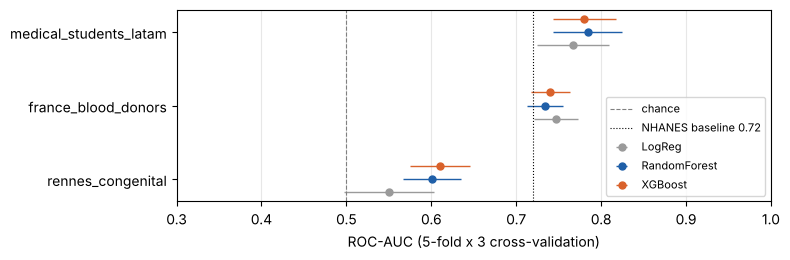

In [9]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [10]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,france_blood_donors,,"age, male, region_Auvergne-Rhône-Alpes, region_Bourgogne..."
1,medical_students_latam,IGM_infeción_presente,"Edad, Lugar_residencia, Estado_civil, Semestre_académico..."
2,rennes_congenital,"N°, Term at maternal infection (weeks' amenorrhea)",Age at blood sampling (days)
